In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("Global_Pollution_Analysis.csv")

df.head()

,Country,Year,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
0,Hungary,2005,272.70,124.27,51.95,94802.83,158.14,5.30,41.11,37078.88,12.56,42.22,20972.96
1,Singapore,2001,86.72,60.34,117.22,56283.92,498.04,6.34,36.44,33128.20,5.23,137.25,34850.41
2,Romania,2016,91.59,83.36,121.72,56256.02,489.51,49.69,9.38,18803.46,13.15,124.47,57773.15
3,Cook Islands,2018,280.61,67.16,93.58,74864.73,145.18,8.91,18.97,9182.27,0.78,67.80,21837.51
4,Djibouti,2008,179.16,127.53,121.55,76862.06,40.38,14.93,34.00,39235.12,12.84,186.52,41379.37


In [3]:
print("Shape of dataset:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

Shape of dataset: (200, 13)

Column names:
Index(['Country', 'Year', 'Air_Pollution_Index', 'Water_Pollution_Index',
       'Soil_Pollution_Index', 'Industrial_Waste (in tons)',
       'Energy_Recovered (in GWh)', 'CO2_Emissions (in MT)',
       'Renewable_Energy (%)', 'Plastic_Waste_Produced (in tons)',
       'Energy_Consumption_Per_Capita (in MWh)', 'Population (in millions)',
       'GDP_Per_Capita (in USD)'],
      dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 13 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Country                                 200 non-null    str    
 1   Year                                    200 non-null    int64  
 2   Air_Pollution_Index                     200 non-null    float64
 3   Water_Pollution_Index                   200 non-null    float64
 4   Soil_Pollution_Index        

In [4]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Country                                   0
Year                                      0
Air_Pollution_Index                       0
Water_Pollution_Index                     0
Soil_Pollution_Index                      0
Industrial_Waste (in tons)                0
Energy_Recovered (in GWh)                 0
CO2_Emissions (in MT)                     0
Renewable_Energy (%)                      0
Plastic_Waste_Produced (in tons)          0
Energy_Consumption_Per_Capita (in MWh)    0
Population (in millions)                  0
GDP_Per_Capita (in USD)                   0
dtype: int64


In [5]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include="str").columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [6]:
print(df.isnull().sum())

Country                                   0
Year                                      0
Air_Pollution_Index                       0
Water_Pollution_Index                     0
Soil_Pollution_Index                      0
Industrial_Waste (in tons)                0
Energy_Recovered (in GWh)                 0
CO2_Emissions (in MT)                     0
Renewable_Energy (%)                      0
Plastic_Waste_Produced (in tons)          0
Energy_Consumption_Per_Capita (in MWh)    0
Population (in millions)                  0
GDP_Per_Capita (in USD)                   0
dtype: int64


In [7]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [8]:
df = df.drop_duplicates()

In [9]:
df.describe()

,Year,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
count,200.000000,200.00000,200.000000,200.000000,200.00000,200.000000,200.000000,200.000000,200.000000,200.00000,200.000000,200.000000
mean,2009.335000,180.62695,115.068100,76.488550,52891.68150,260.448700,24.878100,27.799700,24492.893550,9.43575,104.271300,35307.602400
std,5.765325,67.07331,47.580911,39.692727,27224.49169,147.141923,14.470892,12.361879,14421.356002,5.57567,56.906574,19481.714455
min,2000.000000,50.30000,31.130000,11.150000,1019.37000,11.730000,1.920000,5.040000,542.950000,0.53000,2.320000,1298.700000
25%,2004.000000,134.97250,74.550000,40.895000,31201.97250,118.355000,11.220000,17.700000,12843.882500,4.58250,60.960000,19525.020000
50%,2010.000000,183.38500,112.305000,78.600000,55299.15000,273.140000,25.355000,29.170000,24121.540000,9.22500,104.965000,35043.325000
75%,2014.000000,237.42500,157.477500,109.212500,74805.82500,384.957500,38.550000,37.072500,36516.232500,13.99750,150.930000,51629.547500
max,2019.000000,297.95000,199.320000,149.230000,99739.36000,499.980000,49.690000,49.560000,49852.280000,19.98000,198.820000,69143.140000


In [10]:
print(df.columns.tolist())

['Country', 'Year', 'Air_Pollution_Index', 'Water_Pollution_Index', 'Soil_Pollution_Index', 'Industrial_Waste (in tons)', 'Energy_Recovered (in GWh)', 'CO2_Emissions (in MT)', 'Renewable_Energy (%)', 'Plastic_Waste_Produced (in tons)', 'Energy_Consumption_Per_Capita (in MWh)', 'Population (in millions)', 'GDP_Per_Capita (in USD)']


In [11]:
print("CO2 Emissions:")
print(df["CO2_Emissions (in MT)"].describe())

print("\nIndustrial Waste:")
print(df["Industrial_Waste (in tons)"].describe())

CO2 Emissions:
count    200.000000
mean      24.878100
std       14.470892
min        1.920000
25%       11.220000
50%       25.355000
75%       38.550000
max       49.690000
Name: CO2_Emissions (in MT), dtype: float64

Industrial Waste:
count      200.00000
mean     52891.68150
std      27224.49169
min       1019.37000
25%      31201.97250
50%      55299.15000
75%      74805.82500
max      99739.36000
Name: Industrial_Waste (in tons), dtype: float64


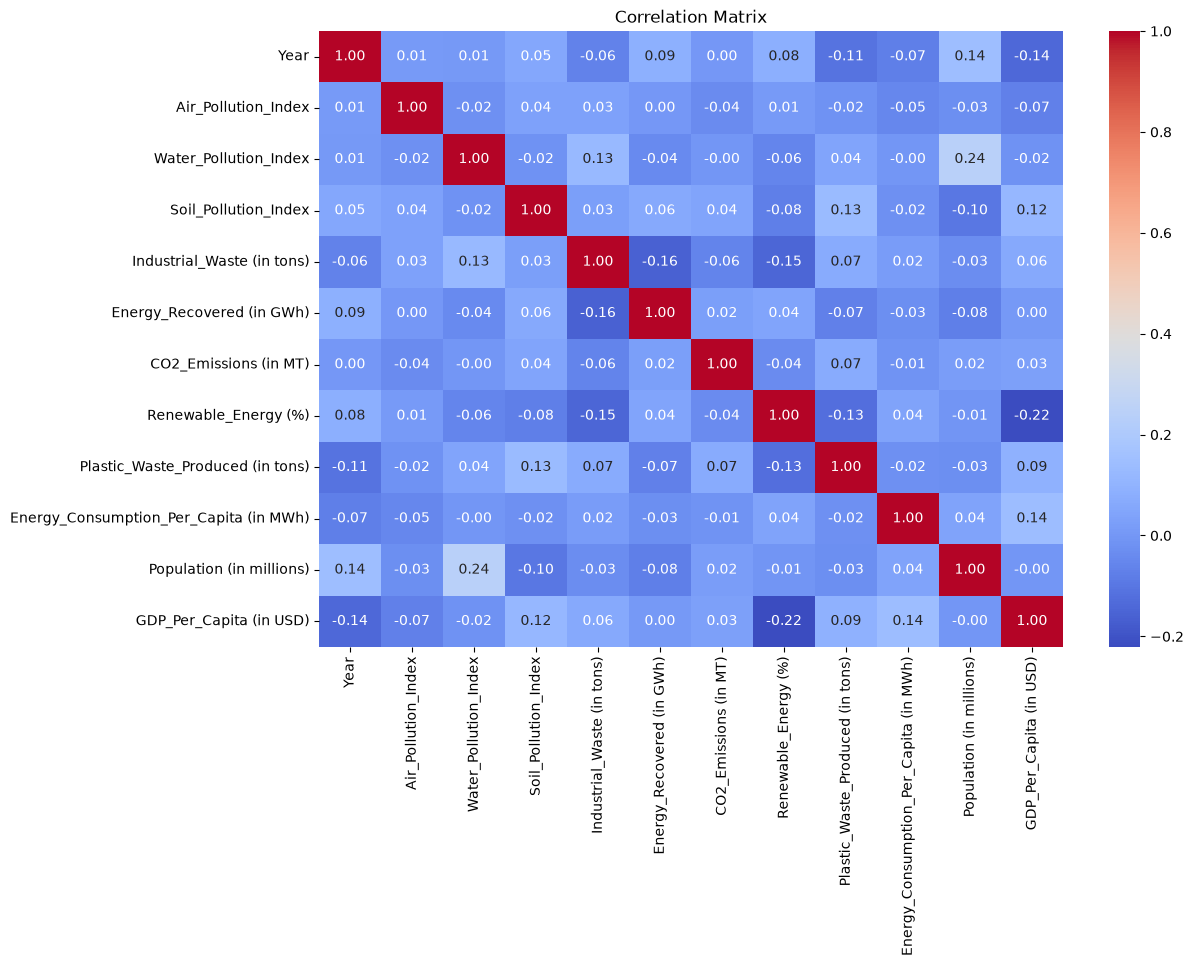

In [12]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix")
plt.show()

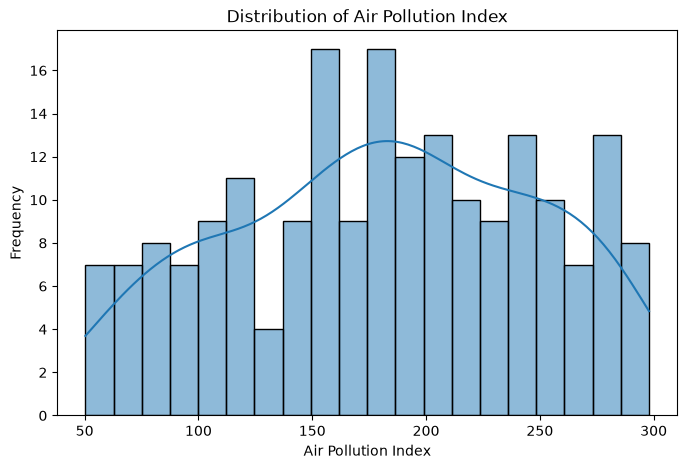

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Air_Pollution_Index"], bins=20, kde=True)

plt.title("Distribution of Air Pollution Index")
plt.xlabel("Air Pollution Index")
plt.ylabel("Frequency")

plt.show()

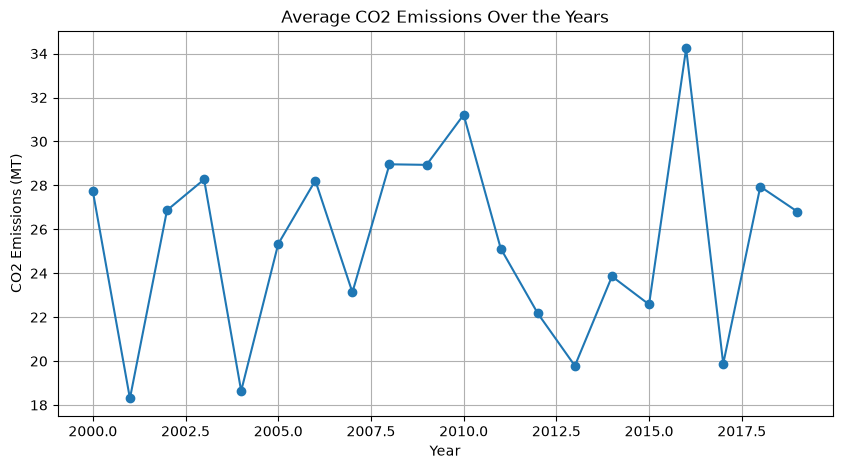

In [14]:
yearly_co2 = df.groupby("Year")["CO2_Emissions (in MT)"].mean()

plt.figure(figsize=(10, 5))

plt.plot(yearly_co2.index, yearly_co2.values, marker="o")

plt.title("Average CO2 Emissions Over the Years")
plt.xlabel("Year")
plt.ylabel("CO2 Emissions (MT)")

plt.grid()
plt.show()

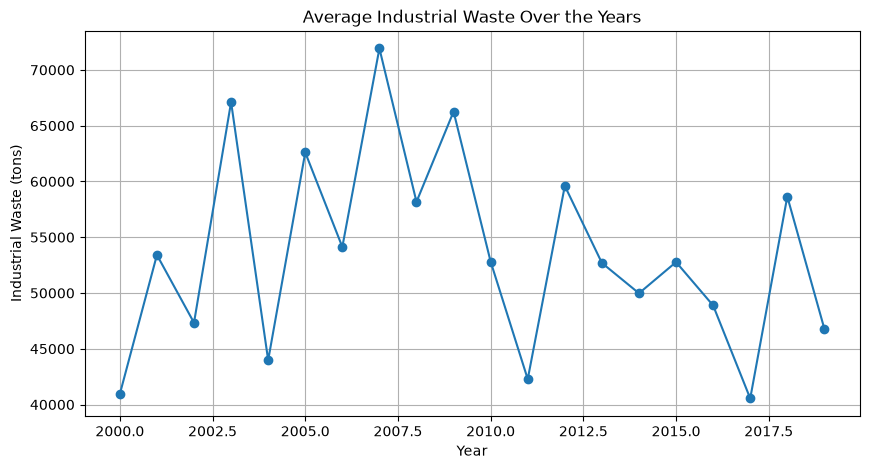

In [15]:
yearly_waste = df.groupby("Year")["Industrial_Waste (in tons)"].mean()

plt.figure(figsize=(10, 5))

plt.plot(yearly_waste.index, yearly_waste.values, marker="o")

plt.title("Average Industrial Waste Over the Years")
plt.xlabel("Year")
plt.ylabel("Industrial Waste (tons)")

plt.grid()
plt.show()

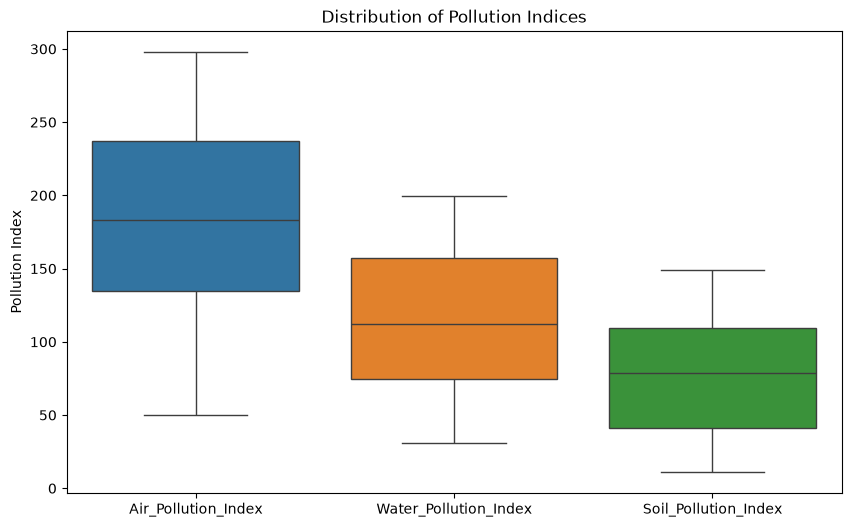

In [16]:
plt.figure(figsize=(10, 6))

pollution_data = df[
    [
        "Air_Pollution_Index",
        "Water_Pollution_Index",
        "Soil_Pollution_Index"
    ]
]

sns.boxplot(data=pollution_data)

plt.title("Distribution of Pollution Indices")
plt.ylabel("Pollution Index")

plt.show()

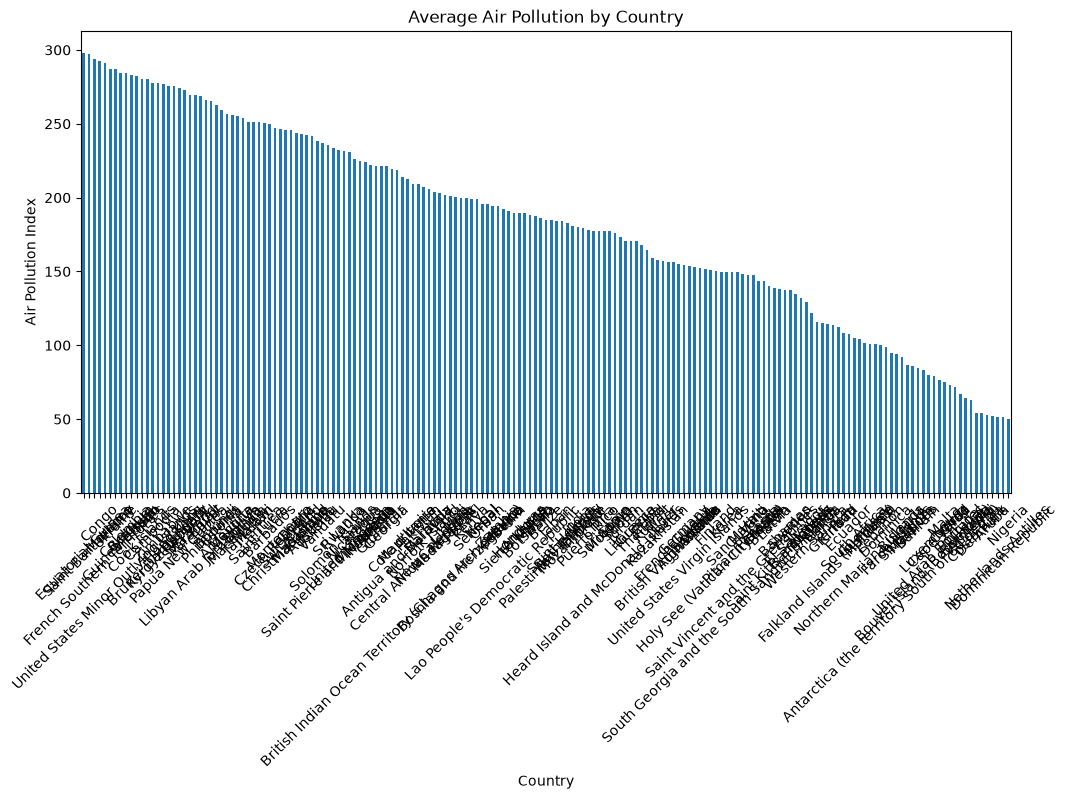

In [17]:
country_pollution = df.groupby("Country")["Air_Pollution_Index"].mean()

country_pollution = country_pollution.sort_values(ascending=False)

plt.figure(figsize=(12, 6))

country_pollution.plot(kind="bar")

plt.title("Average Air Pollution by Country")
plt.xlabel("Country")
plt.ylabel("Air Pollution Index")

plt.xticks(rotation=45)
plt.show()

In [18]:
print(df["Energy_Consumption_Per_Capita (in MWh)"].describe())

count    200.00000
mean       9.43575
std        5.57567
min        0.53000
25%        4.58250
50%        9.22500
75%       13.99750
max       19.98000
Name: Energy_Consumption_Per_Capita (in MWh), dtype: float64


In [19]:
features = [
    "Air_Pollution_Index",
    "CO2_Emissions (in MT)",
    "Industrial_Waste (in tons)"
]

X = df[features]

y = df["Energy_Recovered (in GWh)"]

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [21]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [22]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ -8.69, -4.05,-19.81]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,265.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[13.4 ,12.36,12.16]"


In [23]:
y_pred = linear_model.predict(X_test)

print(y_pred[:10])

[231.28622123 256.28697334 293.35403703 252.21276817 253.08798227
 259.63304458 271.2469819  273.3904576  269.24203413 244.14419677]


In [24]:
r2 = r2_score(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

print("Linear Regression Results")
print("-------------------------")
print("R2 Score:", r2)
print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)

Linear Regression Results
-------------------------
R2 Score: -0.02524886151206318
Mean Squared Error: 24792.810514706925
Mean Absolute Error: 142.10502067262524


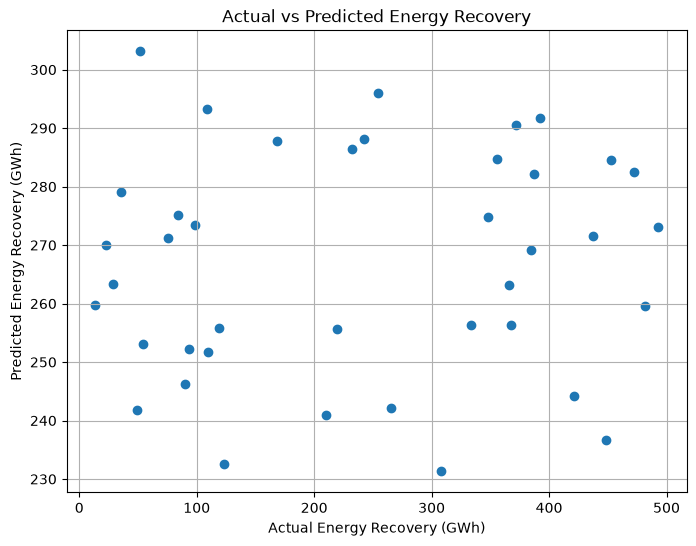

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Energy Recovery (GWh)")
plt.ylabel("Predicted Energy Recovery (GWh)")

plt.title("Actual vs Predicted Energy Recovery")

plt.grid()
plt.show()

In [27]:
df.head()

,Country,Year,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
0,Hungary,2005,272.70,124.27,51.95,94802.83,158.14,5.30,41.11,37078.88,12.56,42.22,20972.96
1,Singapore,2001,86.72,60.34,117.22,56283.92,498.04,6.34,36.44,33128.20,5.23,137.25,34850.41
2,Romania,2016,91.59,83.36,121.72,56256.02,489.51,49.69,9.38,18803.46,13.15,124.47,57773.15
3,Cook Islands,2018,280.61,67.16,93.58,74864.73,145.18,8.91,18.97,9182.27,0.78,67.80,21837.51
4,Djibouti,2008,179.16,127.53,121.55,76862.06,40.38,14.93,34.00,39235.12,12.84,186.52,41379.37


In [28]:
low = df["Air_Pollution_Index"].quantile(0.33)
high = df["Air_Pollution_Index"].quantile(0.66)

def pollution_category(value):
    if value <= low:
        return "Low"
    elif value <= high:
        return "Medium"
    else:
        return "High"

df["Pollution_Severity"] = df["Air_Pollution_Index"].apply(pollution_category)

print("Pollution category limits:")
print("Low:", low)
print("High:", high)

print("\nPollution category distribution:")
print(df["Pollution_Severity"].value_counts())

Pollution category limits:
Low: 150.061
High: 214.31539999999998

Pollution category distribution:
Pollution_Severity
High      68
Low       66
Medium    66
Name: count, dtype: int64


In [40]:
X = df[
    [
        "Air_Pollution_Index",
        "CO2_Emissions (in MT)"
    ]
]

y = df["Pollution_Severity"]

In [41]:
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("Classes:")
print(label_encoder.classes_)

Classes:
['High' 'Low' 'Medium']


In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [43]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [44]:
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [45]:
y_pred = logistic_model.predict(X_test)

print("Predicted classes:")
print(y_pred)

Predicted classes:
[0 1 0 1 2 2 2 2 1 2 0 1 0 2 1 0 0 1 2 0 1 1 0 2 1 0 0 0 1 2 0 2 0 0 1 1 2
 1 2 2]


In [46]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Logistic Regression Results
---------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [47]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

              precision    recall  f1-score   support

        High       1.00      1.00      1.00        14
         Low       1.00      1.00      1.00        13
      Medium       1.00      1.00      1.00        13

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



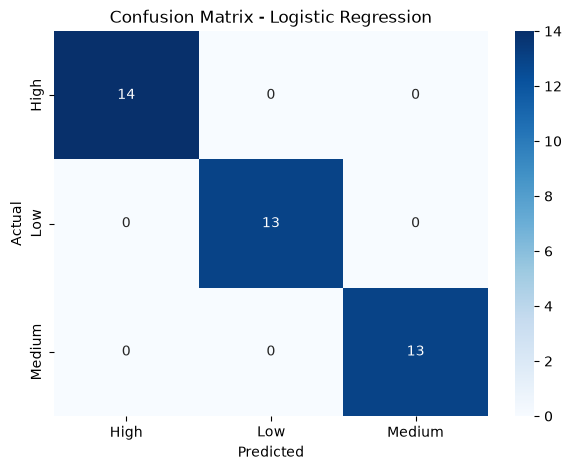

In [48]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

In [49]:
print("Actual classes:")
print(np.unique(y_test))

print("\nPredicted classes:")
print(np.unique(y_pred))

Actual classes:
[0 1 2]

Predicted classes:
[0 1 2]


In [50]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[14  0  0]
 [ 0 13  0]
 [ 0  0 13]]


In [51]:
print("Final Dataset Summary")
print("---------------------")

print("Total Records:", len(df))
print("Number of Countries:", df["Country"].nunique())

print("\nAverage Air Pollution Index:",
      df["Air_Pollution_Index"].mean())

print("Average Water Pollution Index:",
      df["Water_Pollution_Index"].mean())

print("Average Soil Pollution Index:",
      df["Soil_Pollution_Index"].mean())

print("Average CO2 Emissions:",
      df["CO2_Emissions (in MT)"].mean())

print("Average Industrial Waste:",
      df["Industrial_Waste (in tons)"].mean())

print("Average Energy Recovered:",
      df["Energy_Recovered (in GWh)"].mean())

Final Dataset Summary
---------------------
Total Records: 200
Number of Countries: 175

Average Air Pollution Index: 180.62695
Average Water Pollution Index: 115.06810000000002
Average Soil Pollution Index: 76.48854999999999
Average CO2 Emissions: 24.8781
Average Industrial Waste: 52891.681500000006
Average Energy Recovered: 260.44870000000003


In [52]:
country_summary = df.groupby("Country").agg({
    "Air_Pollution_Index": "mean",
    "Water_Pollution_Index": "mean",
    "Soil_Pollution_Index": "mean",
    "CO2_Emissions (in MT)": "mean",
    "Industrial_Waste (in tons)": "mean",
    "Energy_Recovered (in GWh)": "mean"
})

country_summary = country_summary.sort_values(
    "Air_Pollution_Index",
    ascending=False
)

print(country_summary.head(10))

                                      Air_Pollution_Index  \
Country                                                     
Equatorial Guinea                                  297.95   
Saint Barthelemy                                   297.13   
French Southern Territories                        293.91   
Congo                                              292.31   
United States Minor Outlying Islands               290.88   
Morocco                                            287.31   
Ukraine                                            286.81   
Guinea-Bissau                                      284.61   
Colombia                                           284.43   
Belgium                                            282.69   

                                      Water_Pollution_Index  \
Country                                                       
Equatorial Guinea                                    112.73   
Saint Barthelemy                                     172.63   
French Southern

In [53]:
low_energy_recovery = country_summary.sort_values(
    "Energy_Recovered (in GWh)"
)

print(low_energy_recovery.head(10))

                  Air_Pollution_Index  Water_Pollution_Index  \
Country                                                        
Christmas Island               245.99                 157.14   
Zimbabwe                       276.96                  88.33   
Colombia                       284.43                 118.09   
Malta                           75.07                 145.53   
Pakistan                       208.97                 116.78   
Saint Helena                   183.91                 158.91   
Djibouti                       179.16                 127.53   
Tokelau                        238.10                  35.54   
Israel                         199.57                 127.14   
Denmark                         53.84                 110.44   

                  Soil_Pollution_Index  CO2_Emissions (in MT)  \
Country                                                         
Christmas Island                124.72                  49.13   
Zimbabwe                         63.

In [54]:
print(
    df[
        [
            "Air_Pollution_Index",
            "Water_Pollution_Index",
            "Soil_Pollution_Index",
            "CO2_Emissions (in MT)",
            "Industrial_Waste (in tons)",
            "Energy_Recovered (in GWh)"
        ]
    ].corr()["Energy_Recovered (in GWh)"].sort_values(
        ascending=False
    )
)

Energy_Recovered (in GWh)     1.000000
Soil_Pollution_Index          0.064076
CO2_Emissions (in MT)         0.024758
Air_Pollution_Index           0.002997
Water_Pollution_Index        -0.041828
Industrial_Waste (in tons)   -0.161309
Name: Energy_Recovered (in GWh), dtype: float64


## Final Insights

1. The dataset provides information about air, water and soil pollution along with CO2 emissions, industrial waste and energy recovery.

2. The correlation analysis helps identify relationships between pollution indicators, industrial waste, energy consumption and energy recovery.

3. The yearly analysis shows how pollution and waste levels change over time.

4. Linear Regression was used to predict energy recovery from pollution and industrial waste-related features. The model was evaluated using R² Score, Mean Squared Error (MSE) and Mean Absolute Error (MAE).

5. Logistic Regression was used to classify observations into Low, Medium and High pollution categories.

6. The Logistic Regression model achieved 100% accuracy, precision, recall and F1-score on the test data. However, this result should be interpreted carefully because the pollution category was created directly from the Air Pollution Index, which was also used as an input feature.

7. The analysis shows that pollution and industrial waste can be studied not only as environmental problems but also as potential sources for energy recovery through suitable waste-to-energy technologies.

## Recommendations

1. Industries should improve waste segregation and collection so that recyclable and energy-producing waste can be processed efficiently.

2. Waste-to-energy technologies can be considered for suitable industrial and municipal waste streams.

3. Countries with higher pollution and industrial waste levels should focus on better waste management and pollution-control systems.

4. Renewable energy sources should be integrated with waste-to-energy systems wherever technically and economically feasible.

5. Continuous monitoring of air, water and soil pollution can help identify areas requiring immediate environmental improvement.

6. Data-driven prediction models can be used to estimate potential energy recovery and support better environmental planning.

7. Future studies should include additional factors such as waste composition, waste calorific value, technology efficiency and operating costs to improve energy-recovery predictions.

## Conclusion

This project analyzed global pollution and energy-related data using data preprocessing, exploratory data analysis and machine learning techniques.

The exploratory analysis helped identify patterns in pollution, CO2 emissions, industrial waste and energy recovery. Linear Regression was used to predict energy recovery, while Logistic Regression was used to classify pollution severity.

The results demonstrate how machine learning can be applied to environmental datasets to identify patterns and support pollution-management and energy-recovery strategies. However, the classification result should be interpreted carefully because the pollution severity categories were derived from the Air Pollution Index itself.

Overall, the project demonstrates the potential of combining environmental data analysis with machine learning to support pollution reduction and the conversion of suitable waste streams into useful energy.